In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("C:\\Users\\NLH\Downloads\\placement_dataset_100_rows (1).csv")
df

,IQ,CGPA,Placement
0,86,2.40,No
1,134,2.01,No
2,126,3.57,Yes
3,111,3.33,Yes
4,110,3.41,Yes
...,...,...,...
95,100,2.53,No
96,97,2.66,No
97,128,3.04,Yes
98,125,2.88,Yes


## Data PreProcessing for Train Model.............

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   IQ         100 non-null    int64  
 1   CGPA       100 non-null    float64
 2   Placement  100 non-null    str    
dtypes: float64(1), int64(1), str(1)
memory usage: 2.7 KB


In [4]:
df.shape

(100, 3)

In [5]:
df["Placement"] = df["Placement"].map({"Yes":1 ,"No":0})
df

,IQ,CGPA,Placement
0,86,2.40,0
1,134,2.01,0
2,126,3.57,1
3,111,3.33,1
4,110,3.41,1
...,...,...,...
95,100,2.53,0
96,97,2.66,0
97,128,3.04,1
98,125,2.88,1


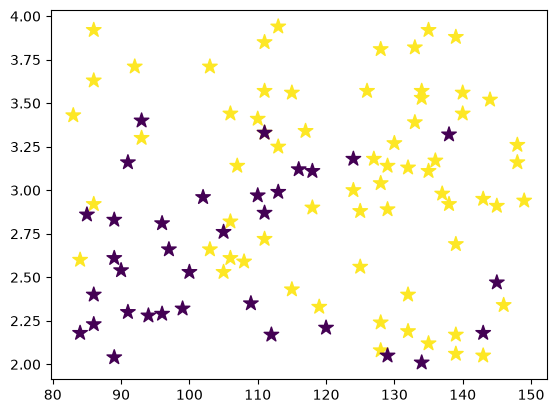

In [6]:
plt.scatter(df["IQ"] , df["CGPA"] , c = df["Placement"] , marker = "*" , s= 120)

In [7]:
X = df.iloc[:,0:2]
X

,IQ,CGPA
0,86,2.40
1,134,2.01
2,126,3.57
3,111,3.33
4,110,3.41
...,...,...
95,100,2.53
96,97,2.66
97,128,3.04
98,125,2.88


In [8]:
Y = df.iloc[:,2]
Y

0     0
1     0
2     1
3     1
4     1
     ..
95    0
96    0
97    1
98    1
99    0
Name: Placement, Length: 100, dtype: int64

## Train__Test Of Model ..............

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test =train_test_split(X,Y,test_size=0.1,random_state = 42)


### X_Train , X_Test , Y_Train , Y_test .....


In [10]:
X_train

,IQ,CGPA
18,139,2.06
30,111,3.33
73,89,2.83
33,119,2.33
90,110,2.97
...,...,...
60,145,2.91
71,93,3.30
14,130,3.27
92,139,3.88


In [11]:
X_test

,IQ,CGPA
83,139,2.69
53,113,3.94
70,136,3.17
45,148,3.26
44,84,2.60
39,124,3.00
22,92,3.71
80,146,2.34
10,117,3.34
0,86,2.40


In [12]:
Y_train

18    1
30    0
73    0
33    1
90    0
     ..
60    1
71    1
14    1
92    1
51    0
Name: Placement, Length: 90, dtype: int64

In [13]:
Y_test

83    1
53    1
70    1
45    1
44    1
39    1
22    1
80    1
10    1
0     0
Name: Placement, dtype: int64


<h2 style = c:"red">Model Training ...........</h2>

In [14]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()

In [15]:
clf.fit(X_train , Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

## Evaluation of Model .........

In [16]:
y_predict = clf.predict(X_test)

In [17]:
Y_test

83    1
53    1
70    1
45    1
44    1
39    1
22    1
80    1
10    1
0     0
Name: Placement, dtype: int64

In [18]:
# Accuracy score is used for checking the accuracy of model .

In [19]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test , y_predict)

0.9

In [20]:
# for showing the model accuracy and testing on plot i import mlxtend function .
# so this graph or plot show the accuracy of model .

C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


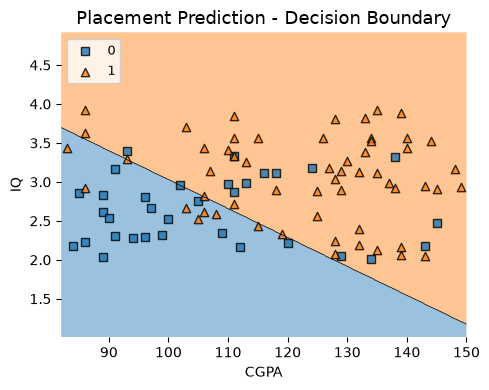

In [21]:
import mlxtend
from mlxtend.plotting import plot_decision_regions

plt.figure(figsize = (5,4) , dpi = 100)
plot_decision_regions(X_train.values , Y_train.values , clf = clf , legend = 2 )
plt.title("Placement Prediction - Decision Boundary", fontsize=13)
plt.xlabel("CGPA", fontsize=10)
plt.ylabel("IQ", fontsize=10)

plt.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## Export The Model for Deployement on Software .......

In [22]:
import pickle

with open("Trained_Model.pkl","wb") as file:
    pickle.dump(clf , file)
    print('Model Saved Succefully ...')

Model Saved Succefully ...


In [23]:
import pickle

with open('Trained_Model.pkl', 'rb') as file:
    clf = pickle.load(file)

print("Model loaded successfully ...")

Model loaded successfully ...


## *************** The Prediction OF Model***********************

In [24]:
prediction_1 = clf.predict([[120,4]])
prediction_2 = clf.predict([[70,2.4]])
prediction_3 = clf.predict([[98,3.4]])
prediction_4 = clf.predict([[100,3.0]])
prediction_5 = clf.predict([[130,2]])
prediction_6 = clf.predict([[94,3.8]])
print('Prediction_1 : ' , prediction_1)
print('Prediction_2 : ' , prediction_2)
print('Prediction_3 : ' , prediction_3)
print('Prediction_4: ' , prediction_4)
print('Prediction_5: ' , prediction_5)
print('Prediction_6 : ' , prediction_6)

Prediction_1 :  [1]
Prediction_2 :  [0]
Prediction_3 :  [1]
Prediction_4:  [0]
Prediction_5:  [1]
Prediction_6 :  [1]


C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\NLH\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\NLH\anaconda3\Li

In [25]:
import pickle
import os

model_path = r"C:\Users\NLH\Desktop\mechine learning\Trained_Model.pkl"

# Check model file
print(os.path.exists(model_path))

# Load trained model
with open(model_path, 'rb') as file:
    clf = pickle.load(file)

print("Model loaded successfully!")

True
Model loaded successfully!


In [26]:
print(type(clf))
print("Model is ready for prediction!")

<class 'sklearn.linear_model._logistic.LogisticRegression'>
Model is ready for prediction!


In [27]:
print("Features:", clf.feature_names_in_)

Features: ['IQ' 'CGPA']


In [28]:
import pandas as pd

# Create input using the original feature names
input_data = pd.DataFrame(
    [[120, 3.5]],
    columns=clf.feature_names_in_
)

# Make prediction
prediction = clf.predict(input_data)

print("Predicted Result:", prediction)

Predicted Result: [1]


In [29]:
probability = clf.predict_proba(input_data)

print("Prediction Probability:", probability)

Prediction Probability: [[0.13528236 0.86471764]]


In [30]:
print("Model Features:", clf.feature_names_in_)

print("Output Classes:", clf.classes_)

Model Features: ['IQ' 'CGPA']
Output Classes: [0 1]


In [31]:
!pip install streamlit